In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import MDAnalysis
from typing import Dict, Tuple
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# functions for analysis of RDCs
# function to parse calculated RDC data
def read_calc_RDCs(filename):
    residues = []
    data = []
    with open(filename,'r') as f:
        lines = f.readlines()
        for line in lines[1:]:
            residues.append(int(line.split(',')[0]))

        for line in lines[1:]:
            dat = np.array(line.split(',')[1:]).astype(float)
            data.append(dat)

    data = np.array(data).T * -1 # account for negative gyromagnetic ratio of 15N

    return residues, data

def scale_rdcs_to_minimize_q(calc, exp, weights, prior='True', scale_matching = 'True'):
    calc = np.array(calc)
    exp = np.array(exp)

    if prior=='True':
        mask_nan = ~np.isnan(weights) # to remove unphysical conformations from averagin
        calc = np.average(calc[mask_nan, :], axis=0)
    else:
        weights = np.nan_to_num(weights,nan=0)
        weights = weights / np.sum(weights)
        calc = np.average(calc, weights=weights, axis=0)

    # if scale_matching - extract datapoints satisfying this
    if scale_matching=='True':
        try:
            prod = calc*exp
            keepidxs = np.where(prod>0)[0]
            #print('keeping {} / {} datapoints for scaling...'.format(keepidxs.shape[0], calc.shape[0]))
            calcfilt = calc[keepidxs]
            expfilt = exp[keepidxs]
            # Compute unconstrained scaling factor
            s = np.sum(calcfilt * expfilt) / np.sum(calcfilt ** 2)
        except:
            print('Warning: no matching RDCs found for scaling, returning nothing...')
            return

    else:
        # Compute unconstrained scaling factor
        s = np.sum(calc * exp) / np.sum(calc ** 2)

    # Constrain s to be ≥ 0 (should be satisfied already if scale_matching)
    s = max(s, 0)

    scaled = s * calc
    q = np.sqrt(np.mean((scaled - exp)**2)) / np.sqrt(np.mean(exp**2))
    q_nonscaled = np.sqrt(np.mean((calc - exp)**2)) / np.sqrt(np.mean(exp**2))

    return scaled, s, q, q_nonscaled

outpath = './RDC_analyses/'

In [2]:
proteins = ['ACTR', 'aSyn', 'd131d', 'drkN', 'NTail']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

for protein in proteins:

    traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

    n_models = len(models)
    ncols=4
    fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4., 3.5 * n_models))

    # load RDC data
    for i in range(len(traj_names)):
        if i==0:
            residues, data = read_calc_RDCs(f'../../MD_DATA/{protein}/RDC/RDC_{traj_names[i]}.csv')
        else:
            residues, tmpdata = read_calc_RDCs(f'../../MD_DATA/{protein}/RDC/RDC_{traj_names[i]}.csv')
            data= np.concatenate((data, tmpdata), axis=0)

    # experimental data
    expres = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/RDC_HN.dat').astype(int)[:,0]
    exprdc = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/RDC_HN.dat')[:,1]
    # remove nan rows
    exp_mask_nan = ~np.isnan(exprdc)
    expres = expres[exp_mask_nan]
    exprdc = exprdc[exp_mask_nan]

    # number of total residues
    prot_length=MDAnalysis.Universe(f'../../MD_DATA/{protein}/protein.pdb').select_atoms('name CA').indices.shape[0]
    # remove first and last residue from experiment
    if expres[0]==1:
        expres=expres[1:]
        exprdc=exprdc[1:]
    elif expres[-1]==prot_length:
        expres=expres[:-1]
        exprdc=exprdc[:-1]

    # sim indices for which there are experiments
    idxs = []
    for ele in expres:
        idx = list(residues).index(ele)
        idxs.append(idx)
    idxs=np.array(idxs).astype(int)
    sim_rdc_residues= np.array(residues)[idxs]
    data = np.array(data)[:,idxs]

    for i, model in enumerate(models):
        exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
        if model in ('rewBV2006', 'rewBV2006ang'):
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")
        else:
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy")

        savedf = pd.DataFrame()
        savedf['Neff'] = phi

        expPF = np.array(exp["PF"][idxs])
        rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
        rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
        r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
        r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

        # calculate RMSE to validation data
        validation_Qfactor = []
        for W in wopt_array:
            scaled, s, q, q_nonscaled = scale_rdcs_to_minimize_q(data, exprdc, W, prior='False', scale_matching='True')
            validation_Qfactor.append(q)
        scaled_prior, s, rdc_prior_q, q_nonscaled = scale_rdcs_to_minimize_q(data, exprdc, np.ones(data.shape[0])/data.shape[0], prior='True', scale_matching='True')

        savedf['RDC_Q'] = validation_Qfactor

        # --- Plot 1: neff vs RMSE with validation data ---
        ax = axes[i, 0]
        ax.scatter(phi, validation_Qfactor, c="tab:red")
        ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("RDC Q-factor")
        ax.set_title(f"{model}")
        ax.set_ylim(0.5 * validation_Qfactor[0], 1.5 * validation_Qfactor[0])

        # --- Plot 2: Per-residue PFs ---
        ax = axes[i, 1]
        ax.set_title(f"Prior: RMSE={rmse_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}")
        ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
        ax.scatter(residues, priorPF, color="tab:blue", label="Prior")
        ax.scatter(residues, rewPF, color="tab:red",label="Posterior")
        ax.set_yscale("log")
        ax.set_ylim(0,300)
        ax.set_xlabel("Residue"); ax.set_ylabel("PF")

        # --- Plot 3: PF exp vs calc prior and posterior ---
        ax = axes[i, 2]
        ax.set_title(f"Prior: r={r_prior:.2f}\nPosterior: r={r_post:.2f}")
        ax.scatter(expPF, priorPF, color="tab:blue", label="Prior")
        ax.scatter(expPF, rewPF, color="tab:red", label="Posterior")
        ax.plot([-10, 1e3], [-10, 1e3], color='black', linestyle='dashed', linewidth=1)
        ax.set_yscale("log")
        ax.set_xscale("log")
        ax.set_ylim(0,300)
        ax.set_xlim(0,300)
        ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

        # --- Plot 4: RDCs calculated prior and posterior ---

        
        ax = axes[i, 3]

        # prior and posterior RMSE
        ax.set_title(f"Prior: Q={rdc_prior_q:.2f}\nPosterior: Q={validation_Qfactor[-1]:.2f}")

        # experimental values
        axlim = np.max(np.abs(exprdc))
        ax.bar(expres, exprdc, color = 'lightblue', alpha=0.5, label='Exp.')
        ax.set_ylim(-axlim*1.3,axlim*1.3)
        ax.set_xlabel("Residue"); ax.set_ylabel(f"RDC (Hz)")

        ax.plot(sim_rdc_residues, scaled_prior, color="tab:blue", label="Prior", linewidth=1.5)
        ax.plot(sim_rdc_residues, scaled, color="tab:red", label="Posterior", linewidth=1.5)

        # set legend
        ax.legend(loc='lower right')

        # save validation diff data 
        savedf.to_csv(outpath+f"{protein}_{model}_RDC_validation.csv")

        
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(outpath+f"{protein}_HDXrew_RDCs.png", dpi=200, bbox_inches="tight")
    plt.close()
        


/tmp/ipykernel_1785006/81616367.py:90: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1785006/81616367.py:101: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1785006/81616367.py:102: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,300)
/tmp/ipykernel_1785006/81616367.py:90: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1785006/81616367.py:101: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1785006/81616367.py:102: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim

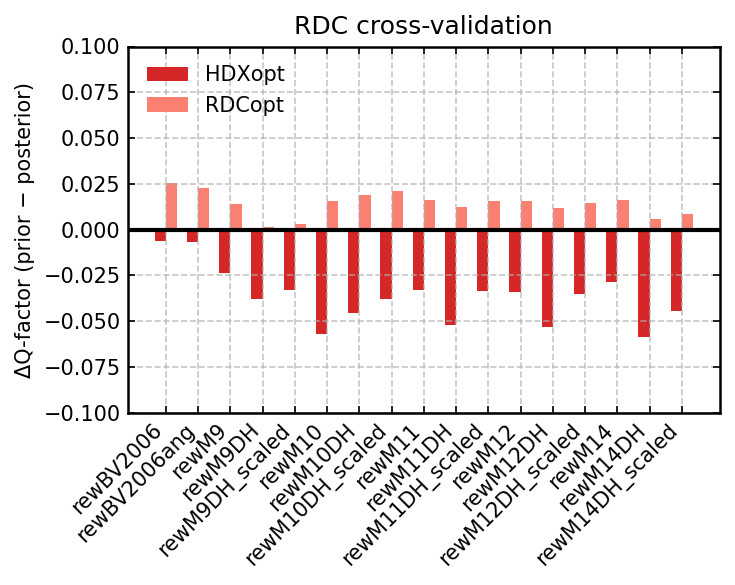

In [3]:
# summary barplot (delta Q-factor prior vs posterior)
# posterior 1 (HDXopt): best HDX fit (final point of the reweighting curve)
# posterior 2 (RDCopt): best validation data fit (minimum point of the reweighting curve - if no improvement this is simply the prior)

proteins = ['ACTR', 'aSyn', 'd131d', 'drkN', 'NTail']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

mean_diff1 = []
mean_diff2 = []

for model in models:

    prior = []
    post1 = []
    post2 = []

    for protein in proteins:
        dat = pd.read_csv(outpath+f'{protein}_{model}_RDC_validation.csv')

        prior.append(list(dat['RDC_Q'])[0])
        post1.append(list(dat['RDC_Q'])[-1])
        post2.append(np.min(dat['RDC_Q']))

    diff1 = np.array(prior)- np.array(post1)
    diff2 = np.array(prior)- np.array(post2)

    mean_diff1.append(np.mean(diff1))
    mean_diff2.append(np.mean(diff2))

df = pd.DataFrame()
df['Model']=models
df['HDXopt'] = mean_diff1
df['RDCopt'] = mean_diff2





x = np.arange(len(df['Model']))          # positions for models
width = 0.35                             # width of the bars

fig, ax = plt.subplots(figsize=(5,4))

ax.bar(x - width/2, df['HDXopt'], width, label='HDXopt', color = 'tab:red')
ax.bar(x + width/2, df['RDCopt'], width, label='RDCopt ', color = 'salmon')

ax.set_ylabel('ΔQ-factor (prior − posterior)')
ax.set_title('RDC cross-validation')
ax.set_xticks(x)
ax.axhline(0, color='black')
ax.set_ylim(-0.1,0.1)
ax.set_xticklabels(df['Model'], rotation=45, ha='right')
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(outpath+f'RDC_validation_summary.png',dpi=300)





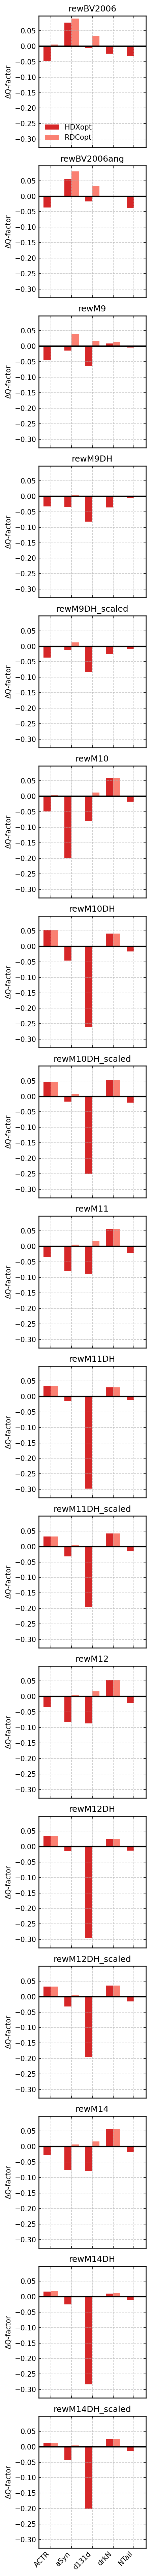

In [4]:
proteins = ['ACTR', 'aSyn', 'd131d', 'drkN', 'NTail']

# ---- Compute ΔRMSE FOR EACH PROTEIN × MODEL ----
rows = []

for model in models:
    for protein in proteins:

        dat = pd.read_csv(outpath + f'{protein}_{model}_RDC_validation.csv')

        prior = list(dat['RDC_Q'])[0]
        post1 = list(dat['RDC_Q'])[-1]
        post2 = np.min(dat['RDC_Q'])

        delta_HDXopt = prior - post1
        delta_RDCopt = prior - post2

        rows.append({
            "Model": model,
            "Protein": protein,
            "HDXopt": delta_HDXopt,
            "RDCopt": delta_RDCopt
        })

df = pd.DataFrame(rows)


# ---- PLOTTING ----
n_models = len(models)
x = np.arange(len(proteins))
width = 0.35

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(3, 3 * n_models),
    sharex=True, sharey=True
)

if n_models == 1:
    axes = [axes]  # make iterable if only one model

# global y-limits
ymin = df[["HDXopt", "RDCopt"]].min().min() * 1.1
ymax = df[["HDXopt", "RDCopt"]].max().max() * 1.1

for idx, model in enumerate(models):
    ax = axes[idx]
    sub = df[df["Model"] == model]

    ax.bar(x - width/2, sub["HDXopt"], width, label="HDXopt", color="tab:red")
    ax.bar(x + width/2, sub["RDCopt"], width, label="RDCopt", color="salmon")

    ax.axhline(0, color="black")
    ax.set_ylim(ymin, ymax)
    ax.set_title(model)
    ax.set_ylabel("ΔQ-factor")

    if idx == 0:
        ax.legend(loc="lower left")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(proteins, rotation=45, ha='right')

plt.tight_layout()
plt.savefig(outpath + "RDC_validation_per_protein_per_model.png", dpi=300)

